In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("results/sample_metadata.csv")
expr_df = pd.read_csv("results/expression_matrix.csv", index_col=0)
log_expr = np.log2(expr_df + 1)

print(f"Samples: {df.shape[0]}, Genes: {expr_df.shape[1]}")

Samples: 7, Genes: 25


In [2]:
# Convert expression to numpy array
expr_array = expr_df.values

print(f"Type: {type(expr_array)}")
print(f"Shape: {expr_array.shape}")       # (samples, genes)
print(f"Data type: {expr_array.dtype}")    # float or int

# Basic operations on the whole matrix at once (vectorized = fast)
print(f"\nOverall mean expression: {expr_array.mean():.1f}")
print(f"Overall max: {expr_array.max()}")
print(f"Overall min: {expr_array.min()}")

# Per-sample stats (axis=1 means across columns = across genes)
sample_means = expr_array.mean(axis=1)
print(f"\nPer-sample mean expression: {sample_means}")

# Per-gene stats (axis=0 means across rows = across samples)
gene_means = expr_array.mean(axis=0)
print(f"\nPer-gene mean expression (first 5): {gene_means[:5]}")

Type: <class 'numpy.ndarray'>
Shape: (7, 25)
Data type: int64

Overall mean expression: 1132.1
Overall max: 3427
Overall min: 145

Per-sample mean expression: [1386.52 1322.16  609.36 1453.96  511.56 1289.   1352.08]

Per-gene mean expression (first 5): [1539.         1495.71428571 1648.71428571 1445.42857143 1350.71428571]


In [3]:
import time

# Create a large fake matrix: 20,000 genes x 100 samples (realistic RNA-seq size)
big_matrix = np.random.negative_binomial(5, 0.005, size=(100, 20000))

# NumPy way (vectorized)
start = time.time()
row_means_numpy = big_matrix.mean(axis=1)
numpy_time = time.time() - start

# Python loop way (slow)
start = time.time()
row_means_loop = []
for i in range(big_matrix.shape[0]):
    total = 0
    for j in range(big_matrix.shape[1]):
        total += big_matrix[i, j]
    row_means_loop.append(total / big_matrix.shape[1])
loop_time = time.time() - start

print(f"NumPy vectorized: {numpy_time:.5f} seconds")
print(f"Python loops:     {loop_time:.5f} seconds")
print(f"NumPy is {loop_time/numpy_time:.0f}x faster")

NumPy vectorized: 0.00210 seconds
Python loops:     0.23055 seconds
NumPy is 110x faster


In [4]:
# Z-score: how many standard deviations away from the mean
# This is how you normalize gene expression for heatmaps and clustering

def zscore_matrix(matrix):
    """Row-wise z-score (per gene across samples)."""
    means = matrix.mean(axis=0)
    stds = matrix.std(axis=0)
    # Avoid division by zero for genes with no variance
    stds[stds == 0] = 1
    return (matrix - means) / stds

z_expr = zscore_matrix(log_expr.values)
z_df = pd.DataFrame(z_expr, index=log_expr.index, columns=log_expr.columns)

print("Before z-scoring:")
print(f"  ISG15 range: {log_expr['ISG15'].min():.1f} to {log_expr['ISG15'].max():.1f}")
print(f"  CD14  range: {log_expr['CD14'].min():.1f} to {log_expr['CD14'].max():.1f}")

print("\nAfter z-scoring (both now on same scale):")
print(f"  ISG15 range: {z_df['ISG15'].min():.1f} to {z_df['ISG15'].max():.1f}")
print(f"  CD14  range: {z_df['CD14'].min():.1f} to {z_df['CD14'].max():.1f}")

Before z-scoring:
  ISG15 range: 8.6 to 11.5
  CD14  range: 8.8 to 10.3

After z-scoring (both now on same scale):
  ISG15 range: -1.7 to 1.2
  CD14  range: -1.8 to 1.5


Correlation matrix shape: (25, 25)

Top correlated gene pairs with ISG15:
GZMB     0.981305
OAS1     0.902586
RSAD2    0.898332
PRF1     0.884870
IFIT1    0.884812
Name: ISG15, dtype: float64


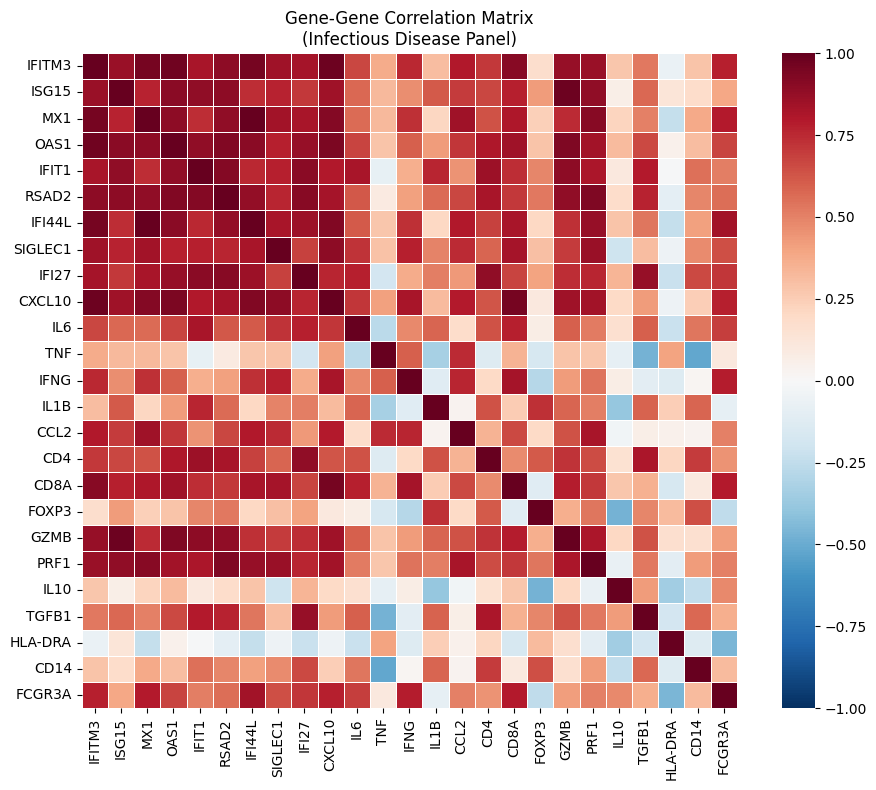

In [5]:
# Pearson correlation between all gene pairs
corr_matrix = log_expr.corr()

print(f"Correlation matrix shape: {corr_matrix.shape}")
print(f"\nTop correlated gene pairs with ISG15:")
isg15_corrs = corr_matrix["ISG15"].drop("ISG15").sort_values(ascending=False)
print(isg15_corrs.head(5))

# Heatmap of correlation matrix
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5,
            xticklabels=True, yticklabels=True)
plt.title("Gene-Gene Correlation Matrix\n(Infectious Disease Panel)")
plt.tight_layout()
plt.savefig("figures/05_gene_correlation.png", dpi=300, bbox_inches="tight")
plt.show()

In [6]:
from numpy.linalg import svd

# PCA is the most common dimensionality reduction in genomics
# Under the hood it's just linear algebra

# Step 1: Center the data (subtract mean per gene)
centered = log_expr.values - log_expr.values.mean(axis=0)

# Step 2: SVD (singular value decomposition) - this IS PCA
U, S, Vt = svd(centered, full_matrices=False)

# Step 3: Project samples into PC space
pcs = U * S  # samples in PC coordinates

# Variance explained by each PC
var_explained = (S ** 2) / (S ** 2).sum() * 100

print(f"PC1 explains {var_explained[0]:.1f}% of variance")
print(f"PC2 explains {var_explained[1]:.1f}% of variance")
print(f"PC1+PC2 together: {var_explained[0] + var_explained[1]:.1f}%")

PC1 explains 71.1% of variance
PC2 explains 12.2% of variance
PC1+PC2 together: 83.3%


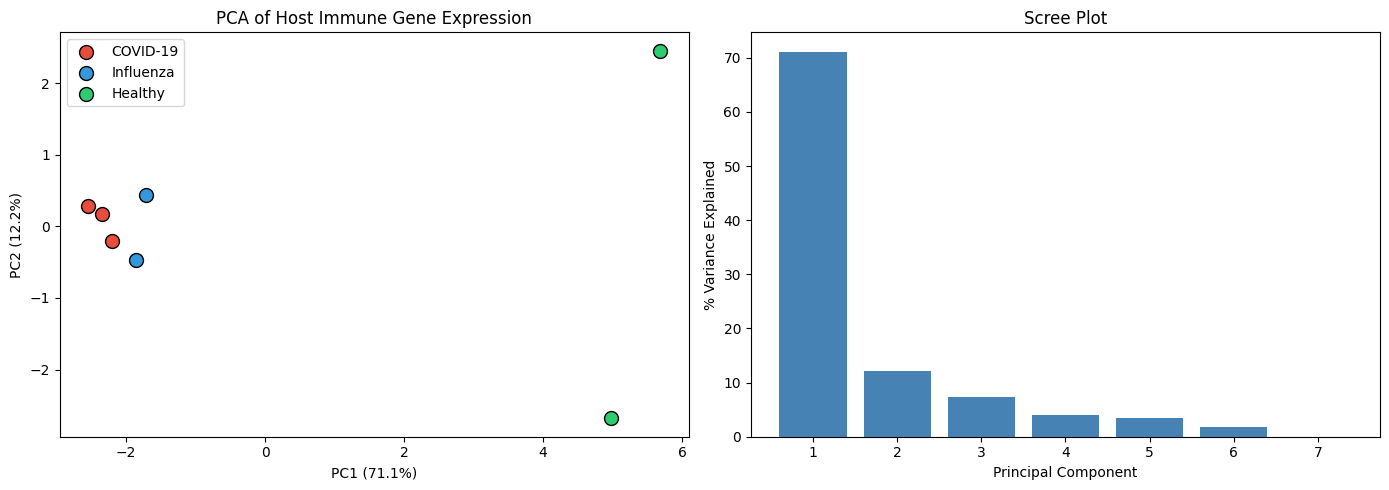

This is the same PCA you'll make with DESeq2 - now you know what's happening under the hood


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# PCA plot colored by condition
colors = {"COVID-19": "#e74c3c", "Influenza": "#3498db", "Healthy": "#2ecc71"}
for condition in df["condition"].unique():
    mask = df["condition"].values == condition
    axes[0].scatter(pcs[mask, 0], pcs[mask, 1], 
                    c=colors[condition], label=condition, s=100, edgecolors="black")
axes[0].set_xlabel(f"PC1 ({var_explained[0]:.1f}%)")
axes[0].set_ylabel(f"PC2 ({var_explained[1]:.1f}%)")
axes[0].set_title("PCA of Host Immune Gene Expression")
axes[0].legend()

# Scree plot (how much each PC contributes)
axes[1].bar(range(1, len(var_explained) + 1), var_explained, color="steelblue")
axes[1].set_xlabel("Principal Component")
axes[1].set_ylabel("% Variance Explained")
axes[1].set_title("Scree Plot")

plt.tight_layout()
plt.savefig("figures/06_pca_analysis.png", dpi=300, bbox_inches="tight")
plt.show()

print("This is the same PCA you'll make with DESeq2 - now you know what's happening under the hood")

In [8]:
# Wide format: what you have (samples as rows, genes as columns)
print("Wide format:")
print(log_expr.head(3))
print(f"Shape: {log_expr.shape}")

# Long format: what ggplot/seaborn needs for grouped plots
long_df = log_expr.copy()
long_df["sample_id"] = long_df.index
long_df["condition"] = df["condition"].values

long_df = long_df.melt(
    id_vars=["sample_id", "condition"],
    var_name="gene",
    value_name="log2_expression"
)

print("\nLong format:")
print(long_df.head(10))
print(f"Shape: {long_df.shape}")
print(f"\nWide had {log_expr.shape[0]} rows, long has {long_df.shape[0]} rows")
print(f"That's {log_expr.shape[0]} samples x {log_expr.shape[1]} genes = {log_expr.shape[0] * log_expr.shape[1]}")

Wide format:
              IFITM3      ISG15        MX1       OAS1      IFIT1      RSAD2  \
sample_id                                                                     
S001       11.094738  10.727070  10.658211  11.185495  10.890264  10.428360   
S002       10.891784  11.471675  10.807355  11.064069  10.499846  10.972262   
S003        8.451211   9.082149   9.359750   8.344296   9.705632   9.240791   

              IFI44L    SIGLEC1      IFI27     CXCL10  ...        CD4  \
sample_id                                              ...              
S001       10.836839  10.970106  10.919608  11.281351  ...  10.425216   
S002       10.708222  10.523562  10.477758  10.733863  ...   9.874981   
S003        8.721099   9.280771  10.067434   8.179909  ...   9.211888   

                CD8A      FOXP3       GZMB      PRF1       IL10     TGFB1  \
sample_id                                                                   
S001       10.051209   9.182394  10.279611  9.095397  10.007027  9.7228

/var/folders/2r/ttm59w257gd1xc0cmvkl7kj40000gn/T/ipykernel_15217/2008493620.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=gene_data, x="condition", y="log2_expression",
/var/folders/2r/ttm59w257gd1xc0cmvkl7kj40000gn/T/ipykernel_15217/2008493620.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=gene_data, x="condition", y="log2_expression",
/var/folders/2r/ttm59w257gd1xc0cmvkl7kj40000gn/T/ipykernel_15217/2008493620.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=gene_data, x="condition", y="log2_expression",
/var

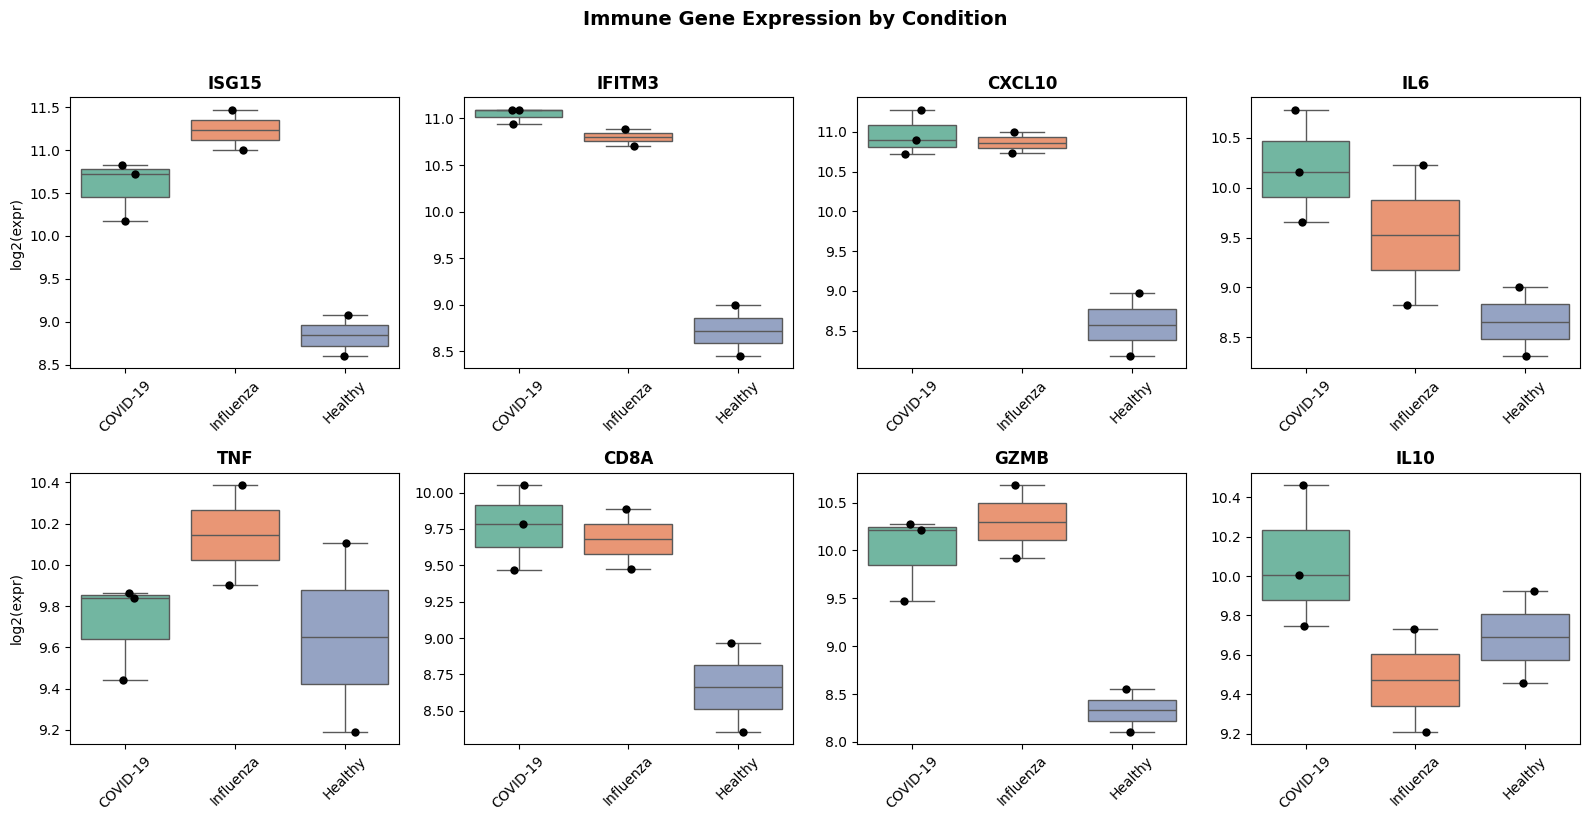

In [9]:
# Pick key immune genes
immune_panel = ["ISG15", "IFITM3", "CXCL10", "IL6", "TNF", "CD8A", "GZMB", "IL10"]

# Filter long dataframe
panel_df = long_df[long_df["gene"].isin(immune_panel)]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, gene in enumerate(immune_panel):
    gene_data = panel_df[panel_df["gene"] == gene]
    sns.boxplot(data=gene_data, x="condition", y="log2_expression", 
                palette="Set2", ax=axes[i])
    sns.stripplot(data=gene_data, x="condition", y="log2_expression",
                  color="black", size=6, ax=axes[i])
    axes[i].set_title(gene, fontsize=12, fontweight="bold")
    axes[i].set_xlabel("")
    axes[i].set_ylabel("log2(expr)" if i % 4 == 0 else "")
    axes[i].tick_params(axis='x', rotation=45)

plt.suptitle("Immune Gene Expression by Condition", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("figures/07_immune_panel.png", dpi=300, bbox_inches="tight")
plt.show()